# Sprint 9 — Tomando Decisões de Negócios Baseadas em Dados

## Preparação dos dados

Neste projeto, vamos priorizar hipóteses para aumentar a receita de uma loja online e analisar os resultados de um teste A/B.

Primeiro, vamos carregar as bibliotecas e os conjuntos de dados necessários para a análise.

### 1. Importação das bibliotecas e carregamento dos dados

In [1]:
# Importando as bibliotecas necessárias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

# Carregando os dados das hipóteses
hypotheses = pd.read_csv('/datasets/hypotheses_us.csv', sep=';')

# Carregando os dados dos pedidos
orders = pd.read_csv('/datasets/orders_us.csv')

# Carregando os dados das visitas
visits = pd.read_csv('/datasets/visits_us.csv')

### 2. Primeira visualização dos dados

In [2]:
# Visualizando as primeiras linhas da tabela de hipóteses
display(hypotheses.head())

# Visualizando as primeiras linhas da tabela de pedidos
display(orders.head())

# Visualizando as primeiras linhas da tabela de visitas
display(visits.head())

,Hypothesis,Reach,Impact,Confidence,Effort
0,Add two new channels for attracting traffic. T...,3,10,8,6
1,Launch your own delivery service. This will sh...,2,5,4,10
2,Add product recommendation blocks to the store...,8,3,7,3
3,Change the category structure. This will incre...,8,3,3,8
4,Change the background color on the main page. ...,3,1,1,1


,transactionId,visitorId,date,revenue,group
0,3667963787,3312258926,2019-08-15,30.4,B
1,2804400009,3642806036,2019-08-15,15.2,B
2,2961555356,4069496402,2019-08-15,10.2,A
3,3797467345,1196621759,2019-08-15,155.1,B
4,2282983706,2322279887,2019-08-15,40.5,B


,date,group,visits
0,2019-08-01,A,719
1,2019-08-02,A,619
2,2019-08-03,A,507
3,2019-08-04,A,717
4,2019-08-05,A,756


In [3]:
# Verificando informações da tabela de hipóteses
hypotheses.info()

print()

# Verificando informações da tabela de pedidos
orders.info()

print()

# Verificando informações da tabela de visitas
visits.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Hypothesis  9 non-null      object
 1   Reach       9 non-null      int64 
 2   Impact      9 non-null      int64 
 3   Confidence  9 non-null      int64 
 4   Effort      9 non-null      int64 
dtypes: int64(4), object(1)
memory usage: 488.0+ bytes

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1197 entries, 0 to 1196
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   transactionId  1197 non-null   int64  
 1   visitorId      1197 non-null   int64  
 2   date           1197 non-null   object 
 3   revenue        1197 non-null   float64
 4   group          1197 non-null   object 
dtypes: float64(1), int64(2), object(2)
memory usage: 46.9+ KB

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62 entries, 0 to 61
Data columns (to

In [4]:
# Verificando os nomes das colunas
print('Colunas de hypotheses:')
print(hypotheses.columns)

print('\nColunas de orders:')
print(orders.columns)

print('\nColunas de visits:')
print(visits.columns)

Colunas de hypotheses:
Index(['Hypothesis', 'Reach', 'Impact', 'Confidence', 'Effort'], dtype='object')

Colunas de orders:
Index(['transactionId', 'visitorId', 'date', 'revenue', 'group'], dtype='object')

Colunas de visits:
Index(['date', 'group', 'visits'], dtype='object')


### 3. Verificação inicial de valores ausentes e duplicados

In [5]:
# Verificando valores ausentes
print('Valores ausentes em hypotheses:')
print(hypotheses.isna().sum())

print('\nValores ausentes em orders:')
print(orders.isna().sum())

print('\nValores ausentes em visits:')
print(visits.isna().sum())

Valores ausentes em hypotheses:
Hypothesis    0
Reach         0
Impact        0
Confidence    0
Effort        0
dtype: int64

Valores ausentes em orders:
transactionId    0
visitorId        0
date             0
revenue          0
group            0
dtype: int64

Valores ausentes em visits:
date      0
group     0
visits    0
dtype: int64


In [6]:
# Verificando linhas completamente duplicadas
print('Duplicados em hypotheses:', hypotheses.duplicated().sum())
print('Duplicados em orders:', orders.duplicated().sum())
print('Duplicados em visits:', visits.duplicated().sum())

Duplicados em hypotheses: 0
Duplicados em orders: 0
Duplicados em visits: 0


## Conclusão inicial

Os conjuntos de dados foram carregados com sucesso. Antes de iniciar a priorização das hipóteses e a análise do teste A/B, vamos verificar os tipos de dados, possíveis valores ausentes, duplicados e inconsistências que possam afetar a análise.

### 5. Pré-processamento dos dados

In [7]:
# Padronizando os nomes das colunas para letras minúsculas
hypotheses.columns = hypotheses.columns.str.lower()
orders.columns = orders.columns.str.lower()
visits.columns = visits.columns.str.lower()

# Convertendo as colunas de data para o tipo datetime
orders['date'] = pd.to_datetime(orders['date'])
visits['date'] = pd.to_datetime(visits['date'])

# Verificando os tipos de dados após a conversão
print('Tipos de dados de orders:')
print(orders.dtypes)

print('\nTipos de dados de visits:')
print(visits.dtypes)

Tipos de dados de orders:
transactionid             int64
visitorid                 int64
date             datetime64[ns]
revenue                 float64
group                    object
dtype: object

Tipos de dados de visits:
date      datetime64[ns]
group             object
visits             int64
dtype: object


### 6. Verificação de usuários presentes nos dois grupos

In [8]:
# Verificando quantos grupos diferentes cada usuário possui
users_groups = (
    orders.groupby('visitorid')['group']
    .nunique()
)

# Selecionando usuários que aparecem nos dois grupos
users_in_both_groups = users_groups[users_groups > 1].index

print('Quantidade de usuários presentes nos dois grupos:')
print(len(users_in_both_groups))

Quantidade de usuários presentes nos dois grupos:
58


## Conclusão do pré-processamento

Os conjuntos de dados foram carregados e analisados inicialmente. Não foram encontrados valores ausentes nem linhas completamente duplicadas.

A tabela de hipóteses precisou ter seu separador corrigido para que suas cinco colunas fossem reconhecidas corretamente. Os nomes das colunas foram padronizados para letras minúsculas e as colunas de data foram convertidas para o formato datetime.

Também foi verificada a presença de usuários em mais de um grupo do teste A/B. Foram identificados 58 usuários presentes simultaneamente nos grupos A e B. Como isso pode interferir na independência dos grupos, esses usuários serão removidos dos dados de pedidos antes da análise do teste A/B.

### 7. Remoção dos usuários presentes nos dois grupos

In [9]:
# Verificando a quantidade de pedidos antes da remoção
print('Quantidade de pedidos antes da remoção:', len(orders))

# Removendo os usuários que aparecem nos dois grupos
orders = orders[
    ~orders['visitorid'].isin(users_in_both_groups)
].copy()

# Verificando a quantidade de pedidos após a remoção
print('Quantidade de pedidos após a remoção:', len(orders))

Quantidade de pedidos antes da remoção: 1197
Quantidade de pedidos após a remoção: 1016


In [10]:
# Conferindo se ainda existem usuários presentes nos dois grupos
check_groups = orders.groupby('visitorid')['group'].nunique()

print(
    'Usuários presentes nos dois grupos após a remoção:',
    (check_groups > 1).sum()
)

Usuários presentes nos dois grupos após a remoção: 0


# Parte 1 — Priorização de Hipóteses

## 1. Priorização das hipóteses pelo framework ICE

O framework ICE utiliza três fatores para priorizar hipóteses: impacto, confiança e esforço.

O ICE é calculado pela fórmula:

ICE = (Impact × Confidence) / Effort

Quanto maior o valor de ICE, maior será a prioridade da hipótese.

In [11]:
# Calculando o ICE para cada hipótese
hypotheses['ICE'] = (
    hypotheses['impact'] * hypotheses['confidence']
) / hypotheses['effort']

# Ordenando as hipóteses do maior para o menor ICE
hypotheses_ice = hypotheses[
    ['hypothesis', 'ICE']
].sort_values(by='ICE', ascending=False)

# Exibindo o resultado
display(hypotheses_ice)

,hypothesis,ICE
8,Launch a promotion that gives users discounts ...,16.200000
0,Add two new channels for attracting traffic. T...,13.333333
7,Add a subscription form to all the main pages....,11.200000
6,Show banners with current offers and sales on ...,8.000000
2,Add product recommendation blocks to the store...,7.000000
1,Launch your own delivery service. This will sh...,2.000000
5,Add a customer review page. This will increase...,1.333333
3,Change the category structure. This will incre...,1.125000
4,Change the background color on the main page. ...,1.000000


### Conclusão do ICE

De acordo com o framework ICE, a hipótese 8 apresenta a maior prioridade, com ICE igual a 16,2. Em seguida aparecem as hipóteses 0 e 7.

Isso indica que a hipótese 8 apresenta a melhor combinação entre impacto, confiança e esforço necessário para sua implementação, considerando os critérios utilizados pelo ICE.

## 2. Priorização das hipóteses pelo framework RICE

O framework RICE considera alcance, impacto, confiança e esforço.

O RICE é calculado pela fórmula:

RICE = (Reach × Impact × Confidence) / Effort

Diferentemente do ICE, o RICE também considera quantos usuários serão alcançados pela hipótese.

In [12]:
# Calculando o RICE para cada hipótese
hypotheses['RICE'] = (
    hypotheses['reach']
    * hypotheses['impact']
    * hypotheses['confidence']
) / hypotheses['effort']

# Ordenando as hipóteses do maior para o menor RICE
hypotheses_rice = hypotheses[
    ['hypothesis', 'RICE']
].sort_values(by='RICE', ascending=False)

# Exibindo o resultado
display(hypotheses_rice)

,hypothesis,RICE
7,Add a subscription form to all the main pages....,112.0
2,Add product recommendation blocks to the store...,56.0
0,Add two new channels for attracting traffic. T...,40.0
6,Show banners with current offers and sales on ...,40.0
8,Launch a promotion that gives users discounts ...,16.2
3,Change the category structure. This will incre...,9.0
1,Launch your own delivery service. This will sh...,4.0
5,Add a customer review page. This will increase...,4.0
4,Change the background color on the main page. ...,3.0


### Conclusão do RICE

De acordo com o framework RICE, a hipótese 7 apresenta a maior prioridade, com RICE igual a 112. Em seguida aparecem a hipótese 2, com RICE igual a 56, e as hipóteses 0 e 6, ambas com RICE igual a 40.

Diferentemente do ICE, o RICE considera também o alcance da hipótese, ou seja, quantos usuários serão afetados pela mudança.

## 3. Comparação entre ICE e RICE

Para entender como a priorização mudou, vamos comparar os valores de ICE e RICE de cada hipótese.

In [13]:
# Criando uma tabela para comparar ICE e RICE
comparison = hypotheses[
    ['hypothesis', 'ICE', 'RICE']
].copy()

# Ordenando a tabela pelo RICE em ordem decrescente
comparison = comparison.sort_values(
    by='RICE',
    ascending=False
)

# Exibindo a comparação
display(comparison)

,hypothesis,ICE,RICE
7,Add a subscription form to all the main pages....,11.200000,112.0
2,Add product recommendation blocks to the store...,7.000000,56.0
0,Add two new channels for attracting traffic. T...,13.333333,40.0
6,Show banners with current offers and sales on ...,8.000000,40.0
8,Launch a promotion that gives users discounts ...,16.200000,16.2
3,Change the category structure. This will incre...,1.125000,9.0
1,Launch your own delivery service. This will sh...,2.000000,4.0
5,Add a customer review page. This will increase...,1.333333,4.0
4,Change the background color on the main page. ...,1.000000,3.0


### Conclusão da comparação entre ICE e RICE

A priorização das hipóteses mudou ao utilizar o RICE.

No ICE, a hipótese 8 ficou em primeiro lugar, seguida pelas hipóteses 0 e 7. Já no RICE, a hipótese 7 passou para o primeiro lugar, seguida pela hipótese 2.

Essa mudança ocorre porque o RICE acrescenta o alcance (`Reach`) ao cálculo. Assim, hipóteses capazes de atingir uma quantidade maior de usuários recebem maior prioridade.

A hipótese 7, por exemplo, ganhou bastante importância no RICE porque possui um alto alcance. Por outro lado, a hipótese 8, que era a primeira colocada pelo ICE, caiu de posição quando o alcance passou a ser considerado.

Portanto, se o objetivo for considerar também quantos usuários serão afetados pela mudança, o RICE indica a hipótese 7 como a principal prioridade.

# Parte 2 — Análise do Teste A/B

## 1. Receita acumulada por grupo

Nesta etapa, vamos calcular a receita acumulada ao longo do teste para os grupos A e B e comparar sua evolução por meio de um gráfico.

In [14]:
# Criando as combinações únicas de data e grupo
dates_groups = orders[['date', 'group']].drop_duplicates()

# Calculando os dados acumulados dos pedidos
orders_aggregated = dates_groups.apply(
    lambda x: orders[
        (orders['date'] <= x['date']) &
        (orders['group'] == x['group'])
    ].agg({
        'date': 'max',
        'group': 'max',
        'transactionid': 'nunique',
        'visitorid': 'nunique',
        'revenue': 'sum'
    }),
    axis=1
).sort_values(by=['date', 'group'])

# Calculando as visitas acumuladas
visits_aggregated = dates_groups.apply(
    lambda x: visits[
        (visits['date'] <= x['date']) &
        (visits['group'] == x['group'])
    ].agg({
        'date': 'max',
        'group': 'max',
        'visits': 'sum'
    }),
    axis=1
).sort_values(by=['date', 'group'])

# Juntando pedidos e visitas acumulados
cumulative_data = orders_aggregated.merge(
    visits_aggregated,
    on=['date', 'group']
)

# Renomeando as colunas para facilitar a análise
cumulative_data.columns = [
    'date',
    'group',
    'orders',
    'buyers',
    'revenue',
    'visits'
]

# Visualizando as primeiras linhas
display(cumulative_data.head())

,date,group,orders,buyers,revenue,visits
0,2019-08-01,A,23,19,2266.6,719
1,2019-08-01,B,17,17,967.2,713
2,2019-08-02,A,42,36,3734.9,1338
3,2019-08-02,B,40,39,3535.3,1294
4,2019-08-03,A,66,60,5550.1,1845


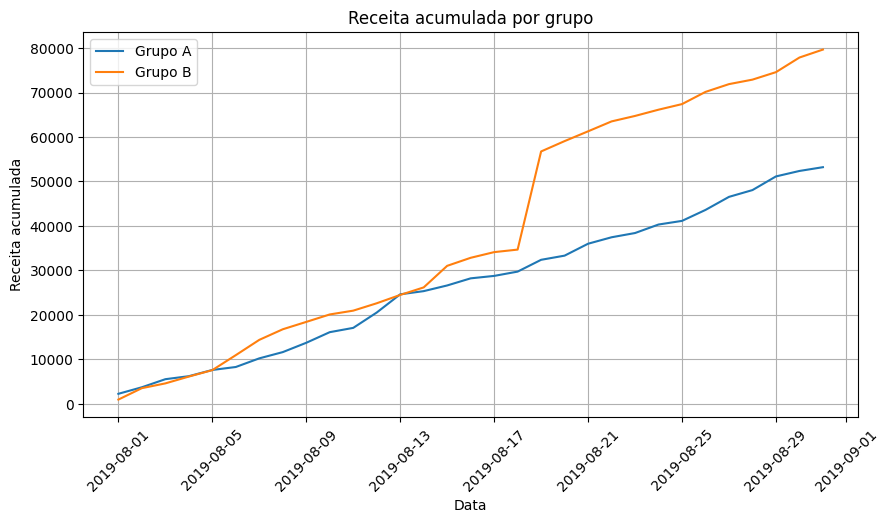

In [15]:
# Separando os dados acumulados do grupo A
cumulative_revenue_a = cumulative_data[
    cumulative_data['group'] == 'A'
][['date', 'revenue', 'orders']]

# Separando os dados acumulados do grupo B
cumulative_revenue_b = cumulative_data[
    cumulative_data['group'] == 'B'
][['date', 'revenue', 'orders']]

# Criando o gráfico da receita acumulada
plt.figure(figsize=(10, 5))

plt.plot(
    cumulative_revenue_a['date'],
    cumulative_revenue_a['revenue'],
    label='Grupo A'
)

plt.plot(
    cumulative_revenue_b['date'],
    cumulative_revenue_b['revenue'],
    label='Grupo B'
)

plt.title('Receita acumulada por grupo')
plt.xlabel('Data')
plt.ylabel('Receita acumulada')
plt.legend()
plt.grid()
plt.xticks(rotation=45)

plt.show()

### Conclusão

A receita acumulada dos dois grupos aumentou ao longo do teste.

No início, os grupos A e B apresentaram resultados próximos. Depois, o grupo B passou a apresentar uma receita acumulada maior que o grupo A.

Também podemos observar um aumento forte na receita do grupo B por volta do dia 18 de agosto. Isso pode ter acontecido por causa de algum pedido com valor muito alto.

Por isso, ainda precisamos analisar os valores dos pedidos e verificar se existem valores anormais que possam estar influenciando o resultado.

## 2. Tamanho médio acumulado dos pedidos por grupo

Agora vamos analisar o tamanho médio acumulado dos pedidos dos grupos A e B.

Para calcular essa métrica, dividimos a receita acumulada pela quantidade acumulada de pedidos de cada grupo.

O objetivo é verificar como o valor médio dos pedidos se comporta ao longo do teste e identificar possíveis diferenças entre os grupos.

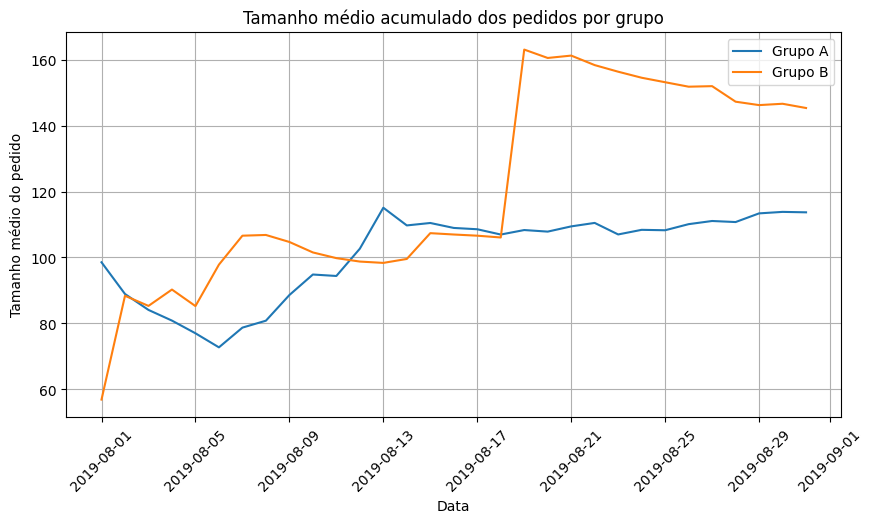

In [16]:
# Calculando o tamanho médio acumulado dos pedidos do grupo A
average_order_a = (
    cumulative_revenue_a['revenue']
    / cumulative_revenue_a['orders']
)

# Calculando o tamanho médio acumulado dos pedidos do grupo B
average_order_b = (
    cumulative_revenue_b['revenue']
    / cumulative_revenue_b['orders']
)

# Criando o gráfico
plt.figure(figsize=(10, 5))

plt.plot(
    cumulative_revenue_a['date'],
    average_order_a,
    label='Grupo A'
)

plt.plot(
    cumulative_revenue_b['date'],
    average_order_b,
    label='Grupo B'
)

# Configurando o gráfico
plt.title('Tamanho médio acumulado dos pedidos por grupo')
plt.xlabel('Data')
plt.ylabel('Tamanho médio do pedido')
plt.legend()
plt.grid()
plt.xticks(rotation=45)

plt.show()

### Conclusão

O tamanho médio acumulado dos pedidos apresentou variações nos dois grupos durante o teste.

O grupo B apresentou um aumento muito grande por volta do dia 18 de agosto e, depois disso, permaneceu acima do grupo A.

Esse aumento pode ter sido causado por um ou mais pedidos de valor muito alto no grupo B. Por isso, ainda precisamos verificar a presença de valores anormais nos dados antes de concluir que o grupo B teve um resultado melhor.

## 3. Diferença relativa no tamanho médio acumulado do pedido

Agora vamos comparar o tamanho médio acumulado dos pedidos do grupo B com o grupo A.

Para isso, vamos juntar os dados dos dois grupos e calcular a diferença relativa entre eles.

O valor 0 no gráfico representa o ponto em que não existe diferença entre os grupos.

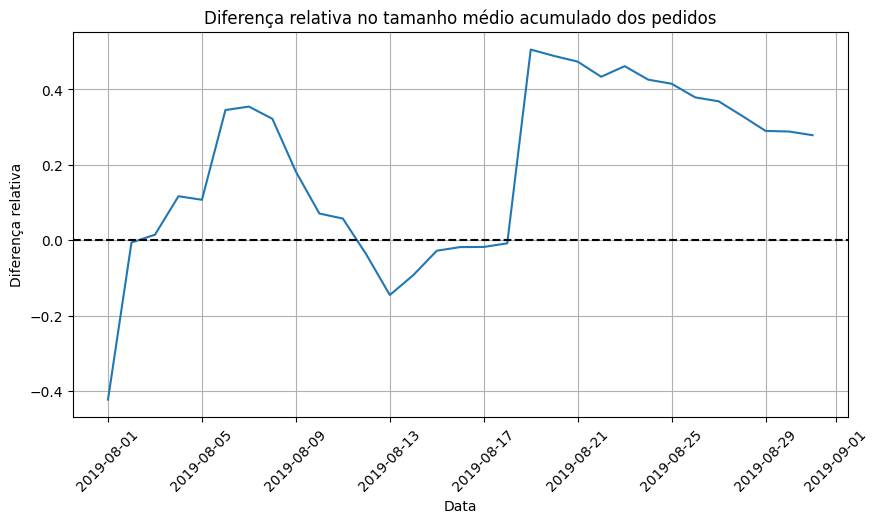

In [17]:
# Juntando os dados acumulados dos grupos A e B pela data
merged_cumulative_revenue = cumulative_revenue_a.merge(
    cumulative_revenue_b,
    on='date',
    suffixes=('_a', '_b')
)

# Calculando a diferença relativa do tamanho médio dos pedidos
relative_difference = (
    (merged_cumulative_revenue['revenue_b'] / merged_cumulative_revenue['orders_b'])
    /
    (merged_cumulative_revenue['revenue_a'] / merged_cumulative_revenue['orders_a'])
    - 1
)

# Criando o gráfico
plt.figure(figsize=(10, 5))

plt.plot(
    merged_cumulative_revenue['date'],
    relative_difference
)

# Adicionando uma linha horizontal em zero
plt.axhline(y=0, color='black', linestyle='--')

# Configurando o gráfico
plt.title('Diferença relativa no tamanho médio acumulado dos pedidos')
plt.xlabel('Data')
plt.ylabel('Diferença relativa')
plt.grid()
plt.xticks(rotation=45)

plt.show()

### Conclusão

A diferença relativa no tamanho médio dos pedidos apresentou bastante variação durante o teste.

Em alguns momentos, o grupo B ficou abaixo do grupo A. Porém, por volta do dia 18 de agosto, ocorreu um aumento muito grande e o grupo B passou a apresentar valores maiores.

Esse salto pode ter sido causado por pedidos de valor muito alto. Por isso, será importante analisar possíveis valores anormais antes de tirar uma conclusão definitiva.

## 4. Taxa de conversão diária por grupo

Agora vamos calcular a taxa de conversão de cada grupo.

A conversão será calculada dividindo a quantidade de pedidos pela quantidade de visitas em cada dia.

Depois, vamos comparar as taxas de conversão diárias dos grupos A e B através de um gráfico.

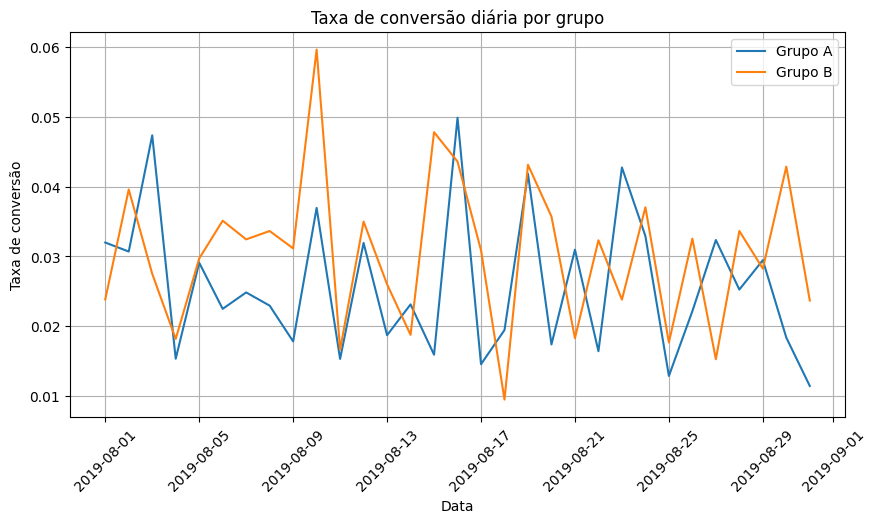

In [18]:
# Calculando a quantidade de pedidos por dia e por grupo
daily_orders = (
    orders.groupby(['date', 'group'])
    .agg({'transactionid': 'nunique'})
    .reset_index()
)

# Renomeando a coluna
daily_orders.columns = ['date', 'group', 'orders']

# Juntando a quantidade de pedidos com a quantidade de visitas
daily_data = daily_orders.merge(
    visits,
    on=['date', 'group']
)

# Calculando a taxa de conversão diária
daily_data['conversion'] = (
    daily_data['orders'] / daily_data['visits']
)

# Separando os grupos A e B
daily_data_a = daily_data[daily_data['group'] == 'A']
daily_data_b = daily_data[daily_data['group'] == 'B']

# Criando o gráfico
plt.figure(figsize=(10, 5))

plt.plot(
    daily_data_a['date'],
    daily_data_a['conversion'],
    label='Grupo A'
)

plt.plot(
    daily_data_b['date'],
    daily_data_b['conversion'],
    label='Grupo B'
)

# Configurando o gráfico
plt.title('Taxa de conversão diária por grupo')
plt.xlabel('Data')
plt.ylabel('Taxa de conversão')
plt.legend()
plt.grid()
plt.xticks(rotation=45)

plt.show()

### Conclusão

As taxas de conversão dos grupos A e B variam bastante durante o período analisado.

Em alguns dias o grupo A apresenta uma conversão maior, enquanto em outros dias o grupo B apresenta resultados melhores.

O grupo B parece apresentar valores maiores em vários momentos, mas somente o gráfico diário não é suficiente para concluir qual grupo teve melhor desempenho.

Por isso, vamos analisar a diferença relativa na conversão cumulativa dos grupos.

## 5. Diferença relativa na conversão cumulativa

Agora vamos analisar a diferença relativa entre as taxas de conversão cumulativa dos grupos B e A.

Primeiro, vamos calcular a conversão acumulada de cada grupo. Depois, vamos juntar os dados dos dois grupos e calcular a diferença relativa.

A linha horizontal em zero representa o ponto em que não existe diferença entre os grupos.

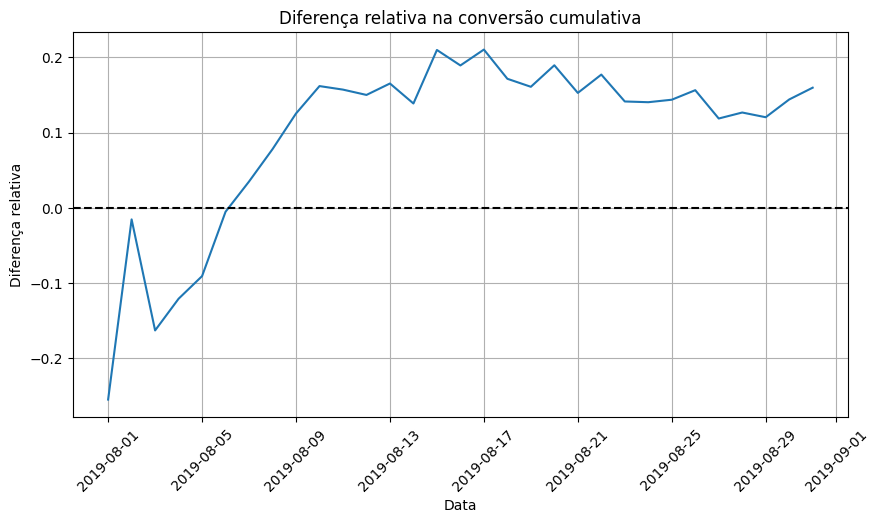

In [19]:
# Calculando a conversão acumulada
cumulative_data['conversion'] = (
    cumulative_data['orders'] / cumulative_data['visits']
)

# Separando os dados acumulados do grupo A
cumulative_data_a = cumulative_data[
    cumulative_data['group'] == 'A'
]

# Separando os dados acumulados do grupo B
cumulative_data_b = cumulative_data[
    cumulative_data['group'] == 'B'
]

# Juntando as conversões acumuladas dos dois grupos
merged_cumulative_conversions = cumulative_data_a[
    ['date', 'conversion']
].merge(
    cumulative_data_b[['date', 'conversion']],
    on='date',
    suffixes=('_a', '_b')
)

# Calculando a diferença relativa do grupo B em relação ao grupo A
relative_conversion = (
    merged_cumulative_conversions['conversion_b']
    / merged_cumulative_conversions['conversion_a']
    - 1
)

# Criando o gráfico
plt.figure(figsize=(10, 5))

plt.plot(
    merged_cumulative_conversions['date'],
    relative_conversion
)

# Adicionando a linha horizontal em zero
plt.axhline(y=0, color='black', linestyle='--')

# Configurando o gráfico
plt.title('Diferença relativa na conversão cumulativa')
plt.xlabel('Data')
plt.ylabel('Diferença relativa')
plt.grid()
plt.xticks(rotation=45)

plt.show()

### Conclusão

No início do teste, a conversão cumulativa do grupo B estava abaixo da conversão do grupo A.

Depois dos primeiros dias, o grupo B passou a apresentar uma conversão maior e permaneceu acima do grupo A durante o restante do período.

No final do teste, a diferença relativa está positiva, indicando uma vantagem do grupo B na conversão.

Ainda precisamos realizar os testes estatísticos para verificar se essa diferença é significativa.

## 6. Percentis da quantidade de pedidos por usuário

Agora vamos analisar quantos pedidos cada usuário realizou durante o teste.

Primeiro, vamos agrupar os pedidos por usuário e contar a quantidade de pedidos de cada um.

Depois, vamos calcular os percentis 95 e 99 para identificar usuários com uma quantidade de pedidos muito acima da maioria.

In [20]:
# Calculando a quantidade de pedidos realizados por cada usuário
orders_by_users = (
    orders.groupby('visitorid')
    .agg({'transactionid': 'nunique'})
    .reset_index()
)

# Renomeando as colunas
orders_by_users.columns = ['visitorid', 'orders']

# Calculando os percentis 95 e 99
percentiles_orders = np.percentile(
    orders_by_users['orders'],
    [95, 99]
)

# Exibindo os resultados
print('Percentil 95:', percentiles_orders[0])
print('Percentil 99:', percentiles_orders[1])

Percentil 95: 1.0
Percentil 99: 2.0


### Conclusão

O percentil 95 é de 1 pedido e o percentil 99 é de 2 pedidos.

Isso mostra que a maioria dos usuários realizou apenas um pedido durante o teste e poucos usuários fizeram mais de dois pedidos.

Portanto, vamos considerar como anômalos os usuários que realizaram mais de 2 pedidos.

## 7. Gráfico de dispersão dos preços dos pedidos

Agora vamos analisar a distribuição dos valores dos pedidos.

Para isso, vamos construir um gráfico de dispersão para identificar possíveis pedidos com valores muito altos.

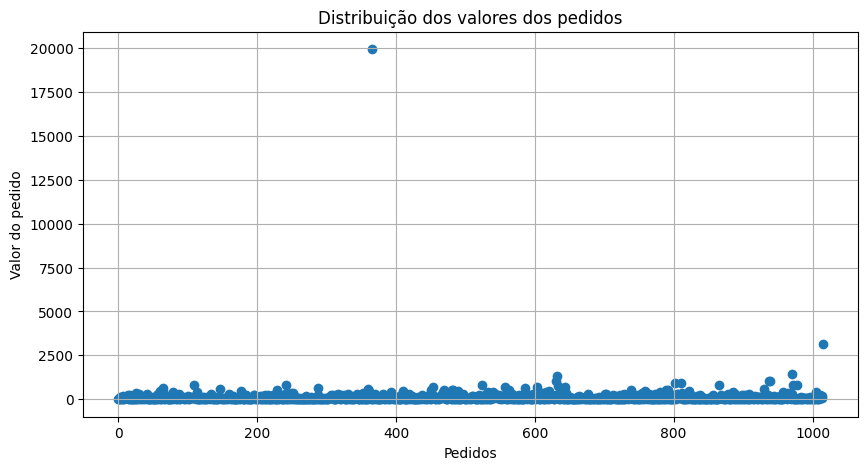

In [21]:
# Criando valores para o eixo X
x_values = pd.Series(range(0, len(orders)))

# Criando o gráfico de dispersão dos valores dos pedidos
plt.figure(figsize=(10, 5))

plt.scatter(
    x_values,
    orders['revenue']
)

# Configurando o gráfico
plt.title('Distribuição dos valores dos pedidos')
plt.xlabel('Pedidos')
plt.ylabel('Valor do pedido')
plt.grid()

plt.show()

### Conclusão

A maior parte dos pedidos possui valores baixos.

Porém, existem alguns pedidos com valores muito maiores que os demais, principalmente um pedido próximo de 20.000.

Esses valores podem ser anomalias e podem influenciar os resultados da análise.

Por isso, no próximo passo vamos calcular os percentis 95 e 99 dos valores dos pedidos para definir um limite para as anomalias.

## 8. Percentis 95 e 99 dos valores dos pedidos

Agora vamos calcular os percentis 95 e 99 dos valores dos pedidos para identificar possíveis valores anormais.

In [22]:
# Calculando os percentis 95 e 99 dos valores dos pedidos
percentiles_revenue = np.percentile(
    orders['revenue'],
    [95, 99]
)

# Exibindo os resultados
print('Percentil 95:', percentiles_revenue[0])
print('Percentil 99:', percentiles_revenue[1])

Percentil 95: 414.275
Percentil 99: 830.3


### Conclusão

O percentil 95 dos valores dos pedidos é aproximadamente 414,28 e o percentil 99 é 830,30.

Isso significa que 99% dos pedidos possuem valores de até aproximadamente 830,30.

Portanto, vamos considerar como anômalos os pedidos com valores acima de 830,30.

## 9. Significância estatística da diferença na conversão — dados brutos

Vamos verificar se existe uma diferença estatisticamente significativa na conversão entre os grupos A e B usando os dados brutos.

In [23]:
# Calculando a quantidade de pedidos por usuário do grupo A
orders_by_users_a = (
    orders[orders['group'] == 'A']
    .groupby('visitorid')['transactionid']
    .nunique()
)

# Calculando a quantidade de pedidos por usuário do grupo B
orders_by_users_b = (
    orders[orders['group'] == 'B']
    .groupby('visitorid')['transactionid']
    .nunique()
)

# Criando as amostras e adicionando os usuários que não fizeram pedidos
sample_a = pd.concat([
    orders_by_users_a,
    pd.Series(
        0,
        index=np.arange(
            visits[visits['group'] == 'A']['visits'].sum()
            - len(orders_by_users_a)
        )
    )
], ignore_index=True)

sample_b = pd.concat([
    orders_by_users_b,
    pd.Series(
        0,
        index=np.arange(
            visits[visits['group'] == 'B']['visits'].sum()
            - len(orders_by_users_b)
        )
    )
], ignore_index=True)

# Calculando o valor-p com o teste de Mann-Whitney
p_value = stats.mannwhitneyu(sample_a, sample_b)[1]

# Calculando o ganho relativo do grupo B
relative_gain = sample_b.mean() / sample_a.mean() - 1

# Exibindo os resultados
print('Valor-p:', round(p_value, 5))
print('Ganho relativo do grupo B:', round(relative_gain, 3))

Valor-p: 0.01102
Ganho relativo do grupo B: 0.16


### Conclusão

O valor-p encontrado foi 0,01102, que é menor que o nível de significância de 0,05.

Portanto, rejeitamos a hipótese nula e concluímos que existe uma diferença estatisticamente significativa na conversão entre os grupos.

Além disso, o grupo B apresentou um ganho relativo de aproximadamente 16% em relação ao grupo A.

## 10. Significância estatística da diferença no tamanho médio dos pedidos — dados brutos

Agora vamos verificar se existe uma diferença estatisticamente significativa no tamanho médio dos pedidos entre os grupos A e B.

Para isso, vamos utilizar os dados brutos e o teste de Mann-Whitney.

In [24]:
# Separando os valores dos pedidos do grupo A
revenue_a = orders[
    orders['group'] == 'A'
]['revenue']

# Separando os valores dos pedidos do grupo B
revenue_b = orders[
    orders['group'] == 'B'
]['revenue']

# Calculando o valor-p com o teste de Mann-Whitney
p_value_revenue = stats.mannwhitneyu(
    revenue_a,
    revenue_b
)[1]

# Calculando o ganho relativo do grupo B
relative_gain_revenue = (
    revenue_b.mean() / revenue_a.mean() - 1
)

# Exibindo os resultados
print('Valor-p:', round(p_value_revenue, 3))
print(
    'Ganho relativo do grupo B:',
    round(relative_gain_revenue, 3)
)

Valor-p: 0.862
Ganho relativo do grupo B: 0.278


### Conclusão

O valor-p encontrado foi 0,862, que é maior que o nível de significância de 0,05.

Portanto, não rejeitamos a hipótese nula e não podemos afirmar que existe uma diferença estatisticamente significativa no tamanho médio dos pedidos entre os grupos.

Apesar disso, o tamanho médio dos pedidos do grupo B foi aproximadamente 27,8% maior que o do grupo A. Essa diferença pode estar sendo influenciada por pedidos com valores muito altos.

## 11. Significância estatística da diferença na conversão — dados filtrados

Agora vamos remover os usuários considerados anômalos e verificar novamente se existe uma diferença estatisticamente significativa na conversão entre os grupos A e B.

Vamos considerar como anômalos os usuários com mais de 2 pedidos ou que realizaram pedidos com valor acima de 830,30.

In [25]:
# Selecionando os usuários com mais de 2 pedidos
users_with_many_orders = orders_by_users[
    orders_by_users['orders'] > 2
]['visitorid']

# Selecionando os usuários que fizeram pedidos acima de 830,30
users_with_expensive_orders = orders[
    orders['revenue'] > 830.30
]['visitorid']

# Juntando os usuários anômalos
abnormal_users = pd.concat(
    [
        users_with_many_orders,
        users_with_expensive_orders
    ]
).drop_duplicates()

# Exibindo a quantidade de usuários anômalos
print('Quantidade de usuários anômalos:', len(abnormal_users))

Quantidade de usuários anômalos: 16


In [26]:
# Removendo os usuários anômalos dos grupos A e B
filtered_orders_a = orders_by_users_a[
    ~orders_by_users_a.index.isin(abnormal_users)
]

filtered_orders_b = orders_by_users_b[
    ~orders_by_users_b.index.isin(abnormal_users)
]

# Criando as amostras filtradas
sample_a_filtered = pd.concat([
    filtered_orders_a,
    pd.Series(
        0,
        index=np.arange(
            visits[visits['group'] == 'A']['visits'].sum()
            - len(filtered_orders_a)
        )
    )
], ignore_index=True)

sample_b_filtered = pd.concat([
    filtered_orders_b,
    pd.Series(
        0,
        index=np.arange(
            visits[visits['group'] == 'B']['visits'].sum()
            - len(filtered_orders_b)
        )
    )
], ignore_index=True)

# Calculando o valor-p
p_value_filtered = stats.mannwhitneyu(
    sample_a_filtered,
    sample_b_filtered
)[1]

# Calculando o ganho relativo do grupo B
relative_gain_filtered = (
    sample_b_filtered.mean() / sample_a_filtered.mean() - 1
)

# Exibindo os resultados
print('Valor-p:', round(p_value_filtered, 5))
print('Ganho relativo do grupo B:', round(relative_gain_filtered, 3))

Valor-p: 0.00695
Ganho relativo do grupo B: 0.189


### Conclusão

O valor-p encontrado foi 0,00695, que é menor que o nível de significância de 0,05.

Portanto, rejeitamos a hipótese nula e concluímos que existe uma diferença estatisticamente significativa na conversão entre os grupos.

Além disso, o grupo B apresentou um ganho relativo de aproximadamente 18,9% em relação ao grupo A.

Mesmo após a remoção dos usuários anômalos, o grupo B continua apresentando uma conversão maior.

## 12. Significância estatística da diferença no tamanho médio dos pedidos — dados filtrados

Agora vamos verificar se existe uma diferença estatisticamente significativa no tamanho médio dos pedidos entre os grupos A e B após remover os usuários anômalos.

Para isso, vamos utilizar os dados filtrados e o teste de Mann-Whitney.

In [27]:
# Separando os valores dos pedidos do grupo A sem usuários anômalos
revenue_a_filtered = orders[
    (orders['group'] == 'A') &
    (~orders['visitorid'].isin(abnormal_users))
]['revenue']

# Separando os valores dos pedidos do grupo B sem usuários anômalos
revenue_b_filtered = orders[
    (orders['group'] == 'B') &
    (~orders['visitorid'].isin(abnormal_users))
]['revenue']

# Calculando o valor-p
p_value_revenue_filtered = stats.mannwhitneyu(
    revenue_a_filtered,
    revenue_b_filtered
)[1]

# Calculando o ganho relativo do grupo B
relative_gain_revenue_filtered = (
    revenue_b_filtered.mean() / revenue_a_filtered.mean() - 1
)

# Exibindo os resultados
print('Valor-p:', round(p_value_revenue_filtered, 5))
print(
    'Ganho relativo do grupo B:',
    round(relative_gain_revenue_filtered, 3)
)

Valor-p: 0.82203
Ganho relativo do grupo B: -0.032


### Conclusão

O valor-p encontrado foi 0,82203, que é maior que o nível de significância de 0,05.

Portanto, não rejeitamos a hipótese nula e não podemos afirmar que existe uma diferença estatisticamente significativa no tamanho médio dos pedidos entre os grupos.

O grupo B apresentou um resultado aproximadamente 3,2% menor que o grupo A.

Após a remoção dos dados anômalos, a diferença no tamanho médio dos pedidos entre os grupos não foi significativa.

## 13. Decisão final

Com base nos resultados obtidos, a melhor decisão é parar o teste e considerar o grupo B como líder.

O grupo B apresentou uma conversão significativamente maior que o grupo A, tanto nos dados brutos quanto nos dados filtrados.

Já o tamanho médio dos pedidos não apresentou diferença estatisticamente significativa entre os grupos.

Por isso, os resultados indicam que o grupo B teve melhor desempenho no teste.